# Baseline: KKR (GL) vs eksperymentalne $T_c$, skład B (Ti, Nb, Zr, Hf, Ta, Mo, W, Y, V, Sc), z poprawką corr2

- **Eksperyment:** `results/Tc_literature.xlsx`.
- **KKR:** `results/comparison.sra.ew0.6.bz10-10-20.gl` (wariant GL: wzór powierzchniowy Gaspari–Gyorffy'ego i całkowita
  DOS Lloyda w 1/N(E_F)).
- **θ_D:** reguła mieszaniny, jak w optymalizacji: $\lambda_{\rm mix} = \lambda_{\rm KKR}(\theta_{\rm KKR}/\theta_{\rm mix})^2$,
  potem McMillan.
- **Zbiory pierwiastków:** stop należy do zbioru, jeśli wszystkie jego pierwiastki są w zbiorze.
  - skład A = Ti, Nb, Zr, Hf, Ta, Mo, W, Y, Re, Ru;
  - skład B = Ti, Nb, Zr, Hf, Ta, Mo, W, Y, V, Sc;
  - A ∪ B = stopy należące do A lub do B.

**Poprawka corr2** (`Tc_corr2`, `process_kkr.compute_tc_corrected`, parametry `TC_CORR_*` w `consts.py`, cel optymalizacji
`--target Tc_corr` od 2026-11-02): McMillan z μ\* = 0.1 i dwiema zmianami:
- θ_D fazy bcc dla **Sc** (215 K zamiast 355 K) w regule mieszaniny, λ przeskalowane o $(\theta_{\rm mix}/\theta_{\rm corr})^2$;
- sprzężenie elektron–paramagnon tylko na **V** (Bose 2009): $\lambda_{es} = x_V\,\alpha_V\,s_V\ln\frac{1}{1-s_V}$,
  $s_V = I_V N_V(E_F)$, α_V = 0.4; $T_c = \frac{\theta}{1.45}\exp\left[-\frac{1.04(1+\lambda+\lambda_{es})}{\lambda-\lambda_{es}-\mu^*(1+0.62(\lambda+\lambda_{es}))}\right]$.

Poprawka dotyczy więc tylko stopów zawierających V lub Sc. **Dla składu A `Tc_corr2 == Tc_mu0.1` dokładnie** (sprawdzane
assertem poniżej), a w A ∪ B zmieniają się tylko wiersze z V/Sc.

Porównywane warianty: (`Tc_mu0.1`, `Tc_mu0.1 (bez poprawki)`), (`Tc_corr2`, `Tc_corr2`). Notebook nie zapisuje plików graficznych.

In [1]:
import json, pathlib, sys
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from scipy import stats
from IPython.display import display
sys.path.insert(0, '../scripts')
import src.process_kkr as pk
RY_EV = 13.605693123
assert (dict(pk.TC_CORR_THETA_BCC_K), dict(pk.TC_CORR_SF_ALPHA), pk.TC_CORR_MU) == ({'Sc': 215.0}, {'V': 0.4}, 0.1), \
    'consts.py nie odpowiada wersji corr2'

SET = 'B'
VARIANTS = [('Tc_mu0.1', 'Tc_mu0.1 (bez poprawki)'), ('Tc_corr2', 'Tc_corr2')]
XLSX    = pathlib.Path('../results/Tc_literature.xlsx')
RESULTS = pathlib.Path('../results/comparison.sra.ew0.6.bz10-10-20.gl')
EXCLUDE = {'NbTa67MoHfW33'}
SET_A = ['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y', 'Re', 'Ru']
SET_B = ['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y', 'V', 'Sc']

# kolumny xlsx (arkusz 'Tc_literature'): A nazwa, B–N skład, S Tc_exp, Z autor, AE status
ELEMENTS = ['Sc', 'Ti', 'Y', 'Zr', 'Nb', 'Mo', 'Ru', 'La', 'Hf', 'Ta', 'W', 'Re', 'V']
COL_NAME, COL_EL0, COL_TC_EXP, COL_AUTHOR, COL_STATUS = 1, 2, 19, 26, 31
COMP_TOL = 2e-3
MARKER = {'single-phase bcc': 'o', 'caution (multiphase etc.)': '^'}
pd.set_option('display.max_rows', 200, 'display.width', 250)

Using AKAIMODBIN: /home/rafal/WORK/HEA/RKKY/cpa2002v010.potential2026/specx


## 0. Dane: eksperyment + KKR (dopasowanie po składzie)

In [2]:
def _val(cell):
    try:
        return float(cell.value)
    except (TypeError, ValueError):
        return np.nan

kkr = {}
for d in sorted(RESULTS.iterdir()):
    p = d / 'results.json'
    if p.is_file():
        j = json.loads(p.read_text())
        x = np.array([float(j.get(e) or 0.0) for e in ELEMENTS])
        kkr[d.name] = (x / x.sum(), j)

def mcmillan(theta, lam, mu):
    denom = lam - mu * (1 + 0.62 * lam)
    return theta / 1.45 * np.exp(-1.04 * (1 + lam) / denom) if denom > 0 else 0.0

ws = openpyxl.load_workbook(XLSX, data_only=True)['Tc_literature']
rows, unmatched = [], []
for r in range(4, ws.max_row + 1):
    name, tc = ws.cell(r, COL_NAME).value, _val(ws.cell(r, COL_TC_EXP))
    x = np.nan_to_num([_val(ws.cell(r, COL_EL0 + i)) for i in range(len(ELEMENTS))])
    if not name or np.isnan(tc) or x.sum() == 0 or name in EXCLUDE:
        continue
    x = x / x.sum()
    k = min(kkr, key=lambda k: np.abs(kkr[k][0] - x).max())
    if np.abs(kkr[k][0] - x).max() > COMP_TOL:
        unmatched.append(name); continue
    j = kkr[k][1]
    els = {e for e, xi in zip(ELEMENTS, x) if xi > 0}
    comp = dict(zip(ELEMENTS, x))
    lam_mix = j['lambda'] * (j['thetaDB_K'] / j['mixture_debye_temperature']) ** 2
    # Tc_corr2: funkcja produkcyjna, na danych w postaci jak w optymalizacji (θ_mix, λ_mix, debye_mode 'mix')
    c = pk.compute_tc_corrected({'thetaDB': j['mixture_debye_temperature'], 'lambda': lam_mix, 'debye_mode': 'mix',
                                 **{f'{e}_Ntot': j.get(f'{e}_Ntot') for e in ELEMENTS}},
                                dict(zip(ELEMENTS, kkr[k][0])))     # skład KKR (θ_mix w results.json liczone z niego)
    status = ws.cell(r, COL_STATUS).value or ''
    rows.append(dict(name=name, author=ws.cell(r, COL_AUTHOR).value or '', kkr_dir=k, Tc_exp=tc,
                     group='caution (multiphase etc.)' if status.startswith('caution') else 'single-phase bcc',
                     in_A=els <= set(SET_A), in_B=els <= set(SET_B), has_VSc=bool(els & {'V', 'Sc'}), **comp,
                     theta_mix=j['mixture_debye_temperature'], lambda_mix=lam_mix,
                     **{'Tc_mu0.1': mcmillan(j['mixture_debye_temperature'], lam_mix, 0.1),
                        'Tc_mu0.2': mcmillan(j['mixture_debye_temperature'], lam_mix, 0.2),
                        'Tc_corr2': c['Tc_corr']},
                     theta_corr=c['theta_corr'], lambda_corr=c['lambda_corr'], lambda_es=c['lambda_es']))
ALL = pd.DataFrame(rows)

# corr2 nie zmienia niczego bez V i Sc
noVSc = ~ALL.has_VSc
assert np.allclose(ALL.loc[noVSc, 'Tc_corr2'], ALL.loc[noVSc, 'Tc_mu0.1'], atol=1e-12, rtol=0)
print(f"Tc_corr2 == Tc_mu0.1 dla wszystkich {noVSc.sum()} wierszy bez V i Sc (w tym całego składu A: {ALL.in_A.sum()})")

DF = {'A': ALL[ALL.in_A], 'B': ALL[ALL.in_B], 'AB': ALL[ALL.in_A | ALL.in_B]}[SET].reset_index(drop=True)
ELSET = {'A': SET_A, 'B': SET_B, 'AB': sorted(set(SET_A) | set(SET_B), key=ELEMENTS.index)}[SET]
print(f"wiersze z Tc_exp i wynikiem KKR (wszystkie): {len(ALL)} (bez wyniku KKR: {unmatched or 'brak'})")
print(f"zbiór {SET}: {len(DF)} wierszy ({(DF.group != 'single-phase bcc').sum()} 'caution'), {DF.kkr_dir.nunique()} składów KKR, "
      f"z V: {(DF.V > 0).sum()}, ze Sc: {(DF.Sc > 0).sum()}, z Re/Ru: {((DF.Re > 0) | (DF.Ru > 0)).sum()}")

Tc_corr2 == Tc_mu0.1 dla wszystkich 74 wierszy bez V i Sc (w tym całego składu A: 74)
wiersze z Tc_exp i wynikiem KKR (wszystkie): 121 (bez wyniku KKR: brak)
zbiór B: 112 wierszy (32 'caution'), 100 składów KKR, z V: 18, ze Sc: 30, z Re/Ru: 0


**Metryki:**
- **kolejność** (najważniejsza dla optymalizacji): Kendall τ, Spearman ρ oraz odsetek par źle uporządkowanych spośród par,
  których eksperymentalne Tc różnią się o ponad 1 K;
- **dopasowanie liniowe** $T_c^{\rm exp} = a\,T_c^{\rm KKR} + b$ (R², Pearson r) oraz prosta przez zero $T_c^{\rm exp} = s\,T_c^{\rm KKR}$;
- **wartości bezwzględne:** MAE, bias (średnia KKR − exp) i mediana stosunku KKR/exp.

In [3]:
def misordered(x, y, dT=1.0):
    good = bad = 0
    for i, j in combinations(range(len(y)), 2):
        if abs(y[i] - y[j]) > dT:
            s = np.sign(y[i] - y[j]) * np.sign(x[i] - x[j])
            good += s > 0; bad += s < 0
    return bad / (good + bad) if good + bad else np.nan

def metrics(x, y):
    lr = stats.linregress(x, y)
    return {'n': len(y), 'Kendall τ': stats.kendalltau(x, y)[0], 'Spearman ρ': stats.spearmanr(x, y)[0],
            'źle uporządk. pary (ΔTc>1K)': misordered(x, y),
            'Pearson r': lr.rvalue, 'R² (LR)': lr.rvalue ** 2, 'a (LR)': lr.slope, 'b (LR) [K]': lr.intercept,
            's (LR przez 0)': np.sum(x * y) / np.sum(x * x),
            'MAE [K]': np.mean(np.abs(x - y)), 'bias [K]': np.mean(x - y), 'mediana KKR/exp': np.median(x / y)}


def summary_table(subsets):
    return pd.DataFrame([{'podzbiór': sn, 'wariant': col, **metrics(s[col].values, s.Tc_exp.values)}
                         for sn, s in subsets.items() if len(s) > 2 for col, _ in VARIANTS]
                        ).set_index(['podzbiór', 'wariant']).round(3)


def linear_plot(df, fit_mask=None, fit_label='wszystkie punkty'):
    # fit_mask: wiersze użyte do dopasowania i metryk; na wykresie zawsze wszystkie punkty
    fit = df if fit_mask is None else df[fit_mask]
    cols = [c for c, _ in VARIANTS]
    lim = (0, max(df.Tc_exp.max(), df[cols].values.max()) * 1.05)
    fig, axes = plt.subplots(1, len(VARIANTS), figsize=(7 * len(VARIANTS), 6.2), sharey=True)
    for ax, (col, lab) in zip(axes, VARIANTS):
        m = metrics(fit[col].values, fit.Tc_exp.values)
        for grp, g in df.groupby('group'):
            for vsc, gg in g.groupby('has_VSc'):
                ax.scatter(gg[col], gg.Tc_exp, marker=MARKER[grp], s=50, edgecolors='k', linewidths=0.4, zorder=3,
                           color='C1' if vsc else 'C0', label=f"{grp}{', z V/Sc' if vsc else ''} (n={len(gg)})")
        xl = np.linspace(*lim, 100)
        ax.plot(xl, xl, ':', color='gray', label='y = x')
        ax.plot(xl, m['a (LR)'] * xl + m['b (LR) [K]'], color='C3', lw=1.8,
                label=f"LR: y = {m['a (LR)']:.2f}x {m['b (LR) [K]']:+.2f}")
        ax.plot(xl, m['s (LR przez 0)'] * xl, '--', color='C2', lw=1.4, label=f"LR przez 0: y = {m['s (LR przez 0)']:.2f}x")
        ax.text(0.03, 0.97, f"dopasowanie i metryki: {fit_label} (n={len(fit)})\n"
                            f"Kendall τ = {m['Kendall τ']:.3f}\nSpearman ρ = {m['Spearman ρ']:.3f}\n"
                            f"Pearson r = {m['Pearson r']:.3f}\nR² = {m['R² (LR)']:.3f}\n"
                            f"MAE = {m['MAE [K]']:.2f} K\nbias = {m['bias [K]']:+.2f} K",
                transform=ax.transAxes, va='top', fontsize=10, bbox=dict(boxstyle='round', fc='white', ec='#cccccc', alpha=0.9))
        ax.set(xlim=lim, ylim=lim, xlabel=f'KKR {col} [K]', title=lab)
        ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='lower right')
    axes[0].set_ylabel('eksperymentalne $T_c$ [K]')
    fig.suptitle(f'Baseline, zbiór {SET} (n={len(df)} na wykresie, dopasowanie: {fit_label}), KKR GL, θ_D mix '
                 f'(pomarańczowe = stopy z V lub Sc)', fontsize=13)
    plt.tight_layout(); plt.show()


def element_panels(df, col, lab):
    present = [e for e in ELSET if (df[e] > 0).any()]
    ncol = 4; nrow = int(np.ceil(len(present) / ncol))
    lim = (0, max(df[col].max(), df.Tc_exp.max()) * 1.05)
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.9 * nrow), sharex=True, sharey=True, squeeze=False)
    for ax, el in zip(axes.flat, present):
        has = df[el] > 0
        ax.scatter(df.loc[~has, col], df.loc[~has, 'Tc_exp'], s=16, color='#d9d9d9', zorder=2)
        vmax = df.loc[has, el].max()
        for grp, g in df[has].groupby('group'):
            ax.scatter(g[col], g.Tc_exp, c=g[el], cmap='viridis', vmin=0, vmax=vmax, marker=MARKER[grp],
                       s=40, edgecolors='k', linewidths=0.3, zorder=3)
        ax.plot(lim, lim, ':', color='gray')
        cb = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, vmax), cmap='viridis'), ax=ax, fraction=0.046, pad=0.02)
        cb.set_label(f'$x_{{\\rm {el}}}$')
        ax.set(xlim=lim, ylim=lim, title=f'{el} (n={has.sum()})')
    for ax in axes.flat[len(present):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel(f'KKR {col} [K]')
    for ax in axes[:, 0]:
        ax.set_ylabel('eksp. $T_c$ [K]')
    fig.suptitle(f'Zbiór {SET}: eksperyment vs KKR ({lab}), kolor = udział pierwiastka, ● single-phase ▲ caution', fontsize=12)
    plt.tight_layout(); plt.show()


def ordering_plot(df):
    fig, axes = plt.subplots(1, len(VARIANTS) + 1, figsize=(6.3 * (len(VARIANTS) + 1), 5.6))
    n = len(df)
    rk_exp = df.Tc_exp.rank(ascending=False)
    for ax, (col, lab) in zip(axes, VARIANTS):
        rk_kkr = df[col].rank(ascending=False)
        for grp, g in df.groupby('group'):
            ax.scatter(rk_kkr[g.index], rk_exp[g.index], marker=MARKER[grp], s=40, edgecolors='k', linewidths=0.3, label=grp)
        ax.plot([1, n], [1, n], ':', color='gray')
        ax.set(xlabel='ranga KKR', ylabel='ranga eksperymentalna', xlim=(0, n + 1), ylim=(0, n + 1),
               title=f"{lab}:  Spearman ρ = {stats.spearmanr(rk_kkr, rk_exp)[0]:.3f}")
        ax.invert_xaxis(); ax.invert_yaxis(); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='lower left')
    DTS = np.arange(0, 4.01, 0.25)
    y = df.Tc_exp.values
    for col, lab in VARIANTS:
        x = df[col].values
        axes[-1].plot(DTS, [1 - misordered(x, y, dT) for dT in DTS], marker='o', label=lab)
    axes[-1].set(xlabel='próg |ΔTc_exp| [K]', ylabel='odsetek par dobrze uporządkowanych',
                 title='Poprawna kolejność par vs różnica Tc', ylim=(0.5, 1.0))
    axes[-1].grid(alpha=0.3); axes[-1].legend()
    plt.tight_layout(); plt.show()
    (c1, _), (c2, _) = VARIANTS
    print(f"Kendall τ między rankingami KKR {c1} i {c2}: {stats.kendalltau(df[c1], df[c2])[0]:.3f}")


def alloy_table(df):
    cols = [c for c, _ in VARIANTS]
    extra = ['theta_corr', 'lambda_es'] if 'Tc_corr2' in cols else []
    tab = df[['name', 'author', 'group', 'Tc_exp', 'theta_mix', 'lambda_mix', *extra, *cols]].copy()
    for c in cols:
        tab[f'KKR/exp {c}'] = tab[c] / tab.Tc_exp
    return tab.sort_values('Tc_exp', ascending=False).reset_index(drop=True).round(3)

## 1. Metryki

In [4]:
SUBSETS = {'skład B, wszystkie': DF, 'tylko single-phase bcc': DF[DF.group == 'single-phase bcc'],
    'z V': DF[DF.V > 0], 'ze Sc': DF[DF.Sc > 0], 'ze Sc, single-phase': DF[(DF.Sc > 0) & (DF.group == 'single-phase bcc')],
    'z V lub Sc': DF[DF.has_VSc], 'bez V i Sc (wspólne z A)': DF[~DF.has_VSc], 'z Ti ≥ 20 %': DF[DF.Ti >= 0.2]}
summary_table(SUBSETS)

n  Kendall τ  Spearman ρ  źle uporządk. pary (ΔTc>1K)  Pearson r  R² (LR)  a (LR)  b (LR) [K]  s (LR przez 0)  MAE [K]  bias [K]  mediana KKR/exp
podzbiór                 wariant                                                                                                                                                      
skład B, wszystkie       Tc_mu0.1  112      0.458       0.647                        0.198      0.607    0.369   0.336       4.321           0.905    1.667     0.001            1.031
                         Tc_corr2  112      0.656       0.852                        0.071      0.810    0.656   0.423       3.671           0.889    1.459     0.194            1.047
tylko single-phase bcc   Tc_mu0.1   80      0.618       0.802                        0.108      0.795    0.633   0.496       2.874           0.864    1.349     0.588            1.091
                         Tc_corr2   80      0.682       0.871                        0.060      0.868    0.754   0.500       3.045           0.896    1.305     0.204            1.055
z V                      Tc_mu0.1   18      0.290       0.376                        0.295      0.385    0.148   0.178       3.726           0.737    1.717     1.381            1.243
                         Tc_corr2   18      0.251       0.345                        0.318      0.238    0.056   0.134       4.308           1.111    1.419    -0.912            0.796
ze Sc                    Tc_mu0.1   30      0.534       0.719                        0.145      0.529    0.280   0.280       5.495           1.174    2.183    -1.787            0.713
                         Tc_corr2   30      0.668       0.830                        0.079      0.681    0.463   0.320       4.624           0.889    1.602     0.295            1.085
ze Sc, single-phase      Tc_mu0.1    6      0.966       0.986                        0.000      0.974    0.949   0.812       1.227           1.012    0.556    -0.238            0.944
                         Tc_corr2    6      0.828       0.928                        0.091      0.927    0.860   0.663       1.436           0.864    1.080     0.636            1.101
z V lub Sc               Tc_mu0.1   47      0.159       0.225                        0.479      0.155    0.024   0.106       5.598           0.980    2.033    -0.594            0.904
                         Tc_corr2   47      0.637       0.818                        0.114      0.751    0.565   0.406       3.734           0.920    1.538    -0.133            0.958
bez V i Sc (wspólne z A) Tc_mu0.1   65      0.667       0.846                        0.046      0.840    0.706   0.431       3.650           0.872    1.402     0.431            1.061
                         Tc_corr2   65      0.667       0.846                        0.046      0.840    0.706   0.431       3.650           0.872    1.402     0.431            1.061
z Ti ≥ 20 %              Tc_mu0.1   52      0.292       0.433                        0.309      0.445    0.198   0.317       4.570           1.087    1.771    -1.067            0.827
                         Tc_corr2   52      0.656       0.834                        0.104      0.809    0.654   0.506       3.477           1.051    1.373    -0.820            0.828

## 2. KKR vs eksperyment, dopasowanie liniowe

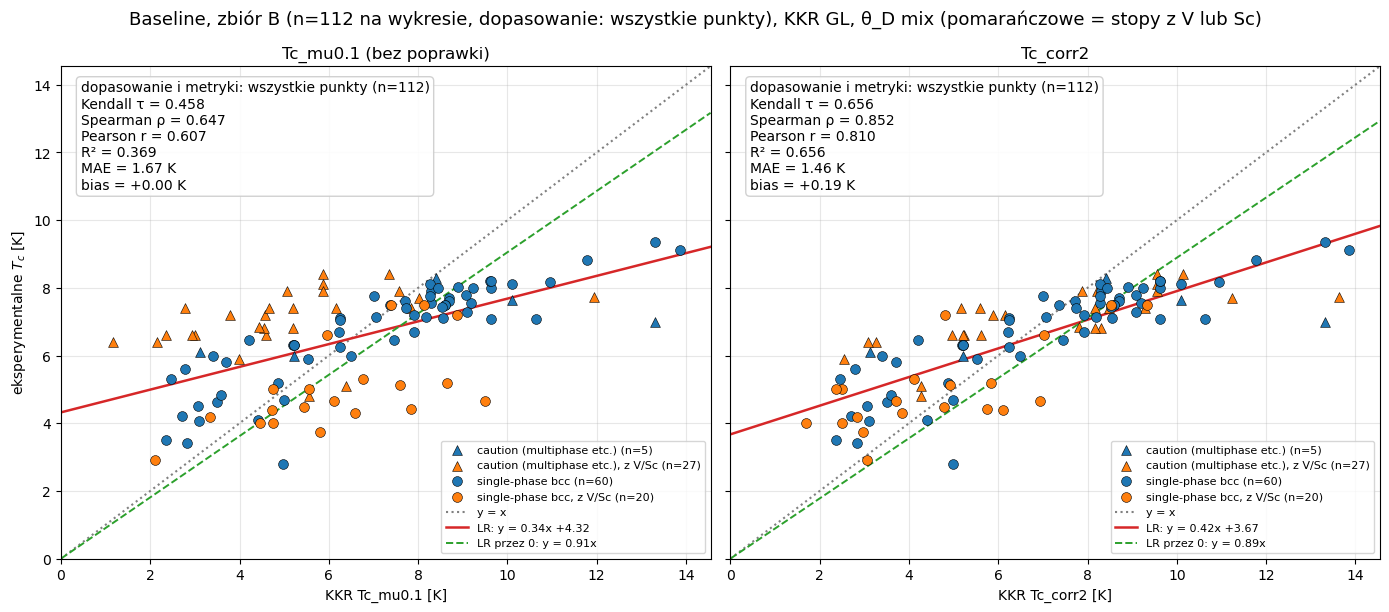

In [5]:
linear_plot(DF)

### 2b. Dopasowanie tylko na próbkach single-phase bcc

Na wykresie są wszystkie punkty (▲ = caution, wielofazowe itp.), ale proste i metryki w ramce są liczone wyłącznie na
próbkach jednofazowych (●). Te same metryki są w tabeli w sekcji 1, w wierszu „tylko single-phase bcc”.

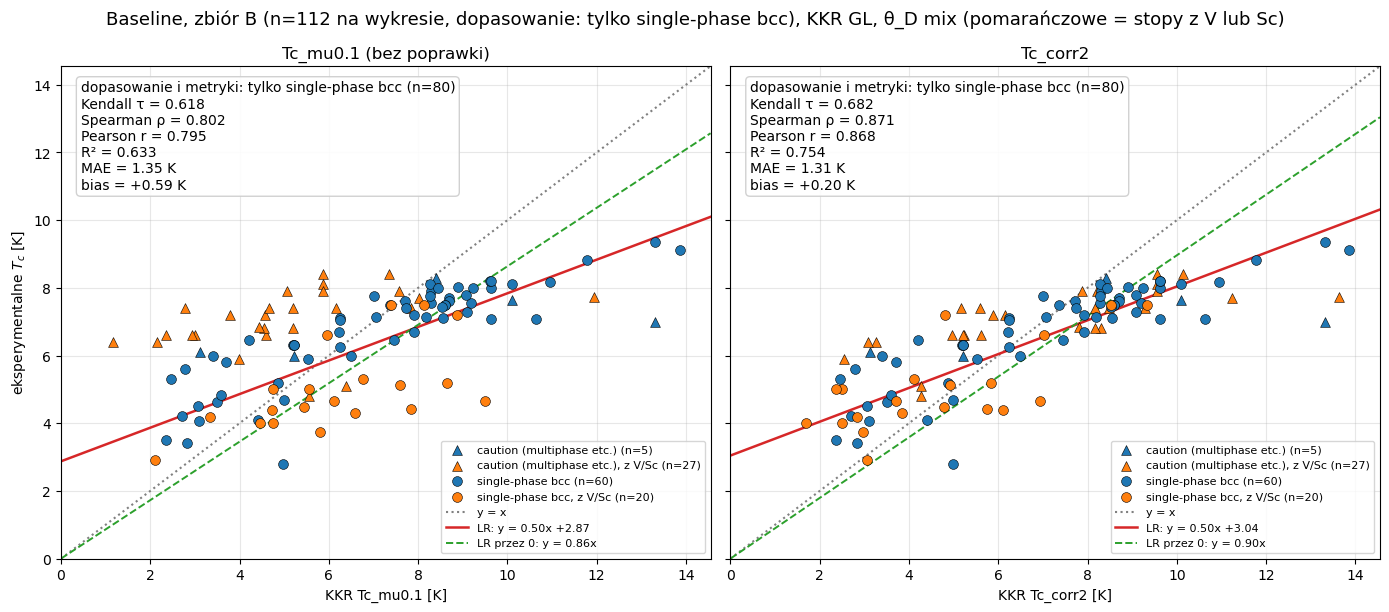

In [6]:
linear_plot(DF, fit_mask=DF.group == 'single-phase bcc', fit_label='tylko single-phase bcc')

## 3. Wykresy kolorowane udziałem pierwiastka

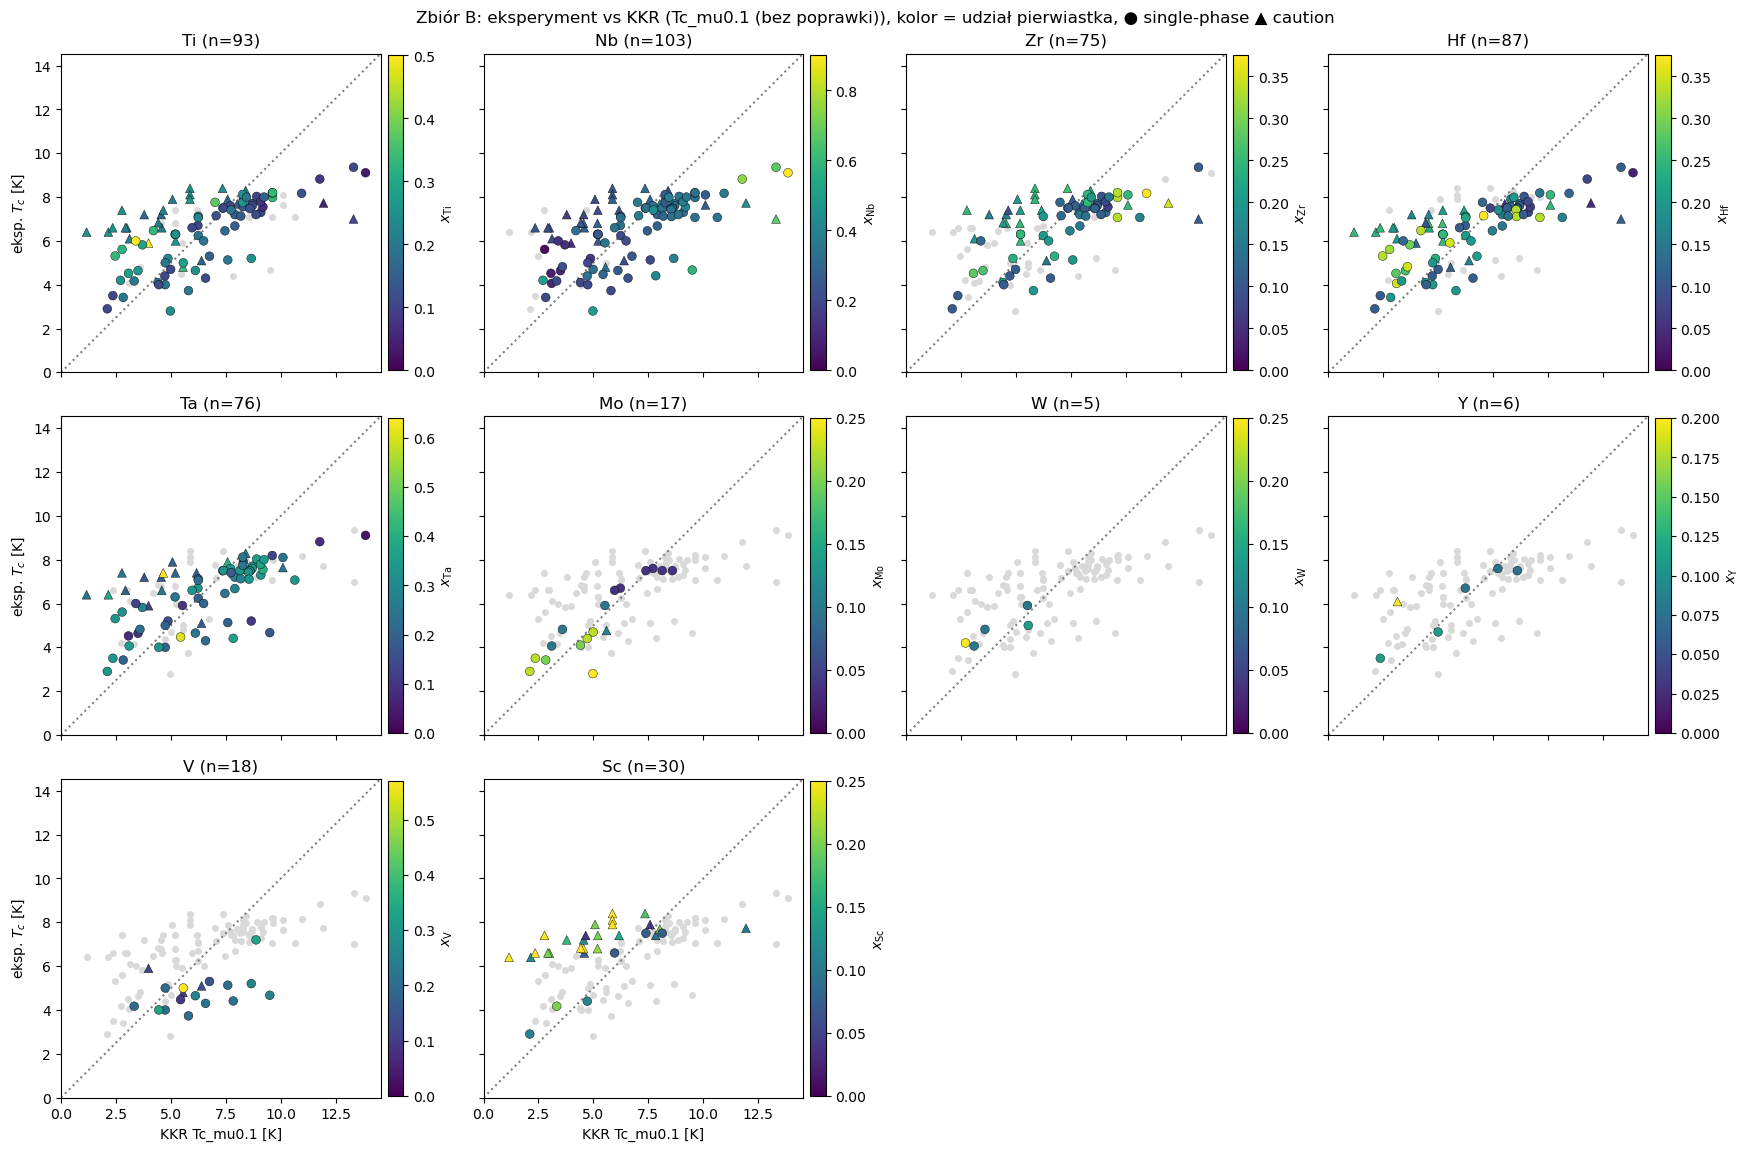

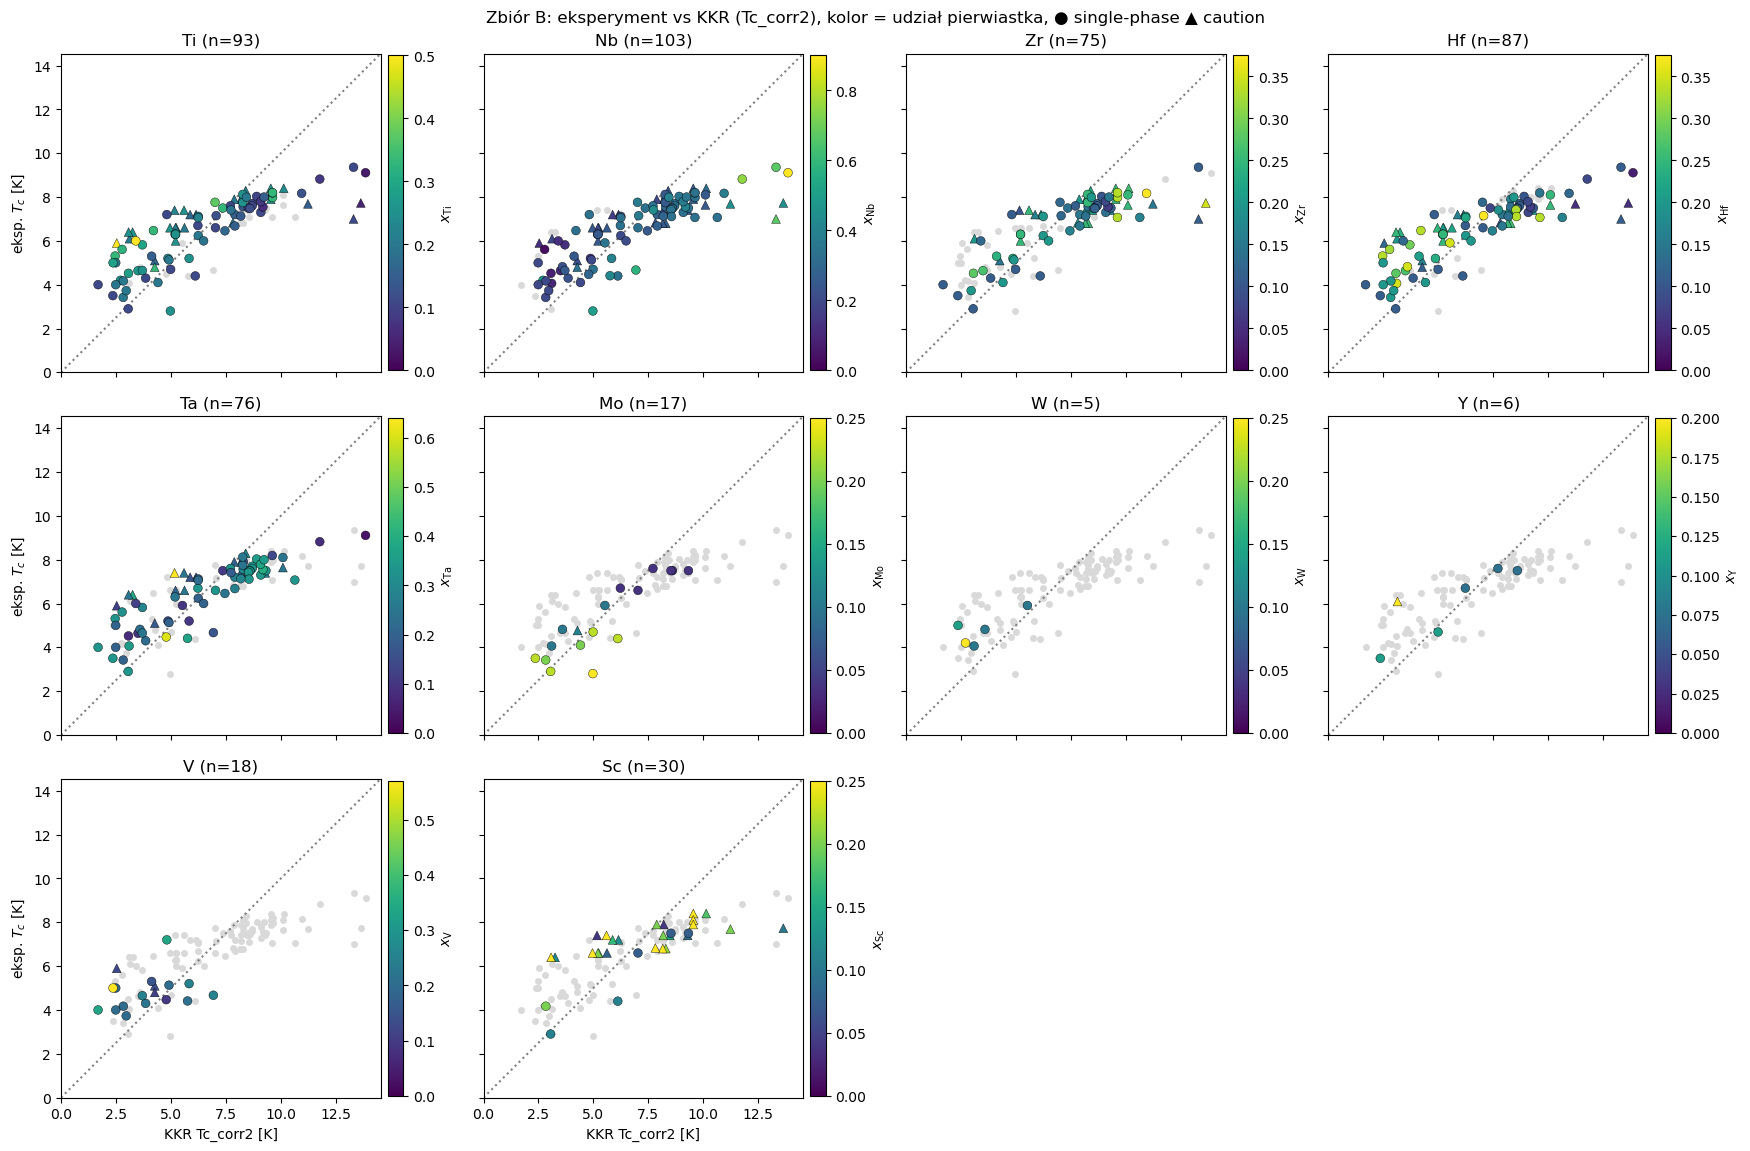

In [7]:
for col, lab in VARIANTS:
    element_panels(DF, col, lab)

## 4. Zachowanie kolejności

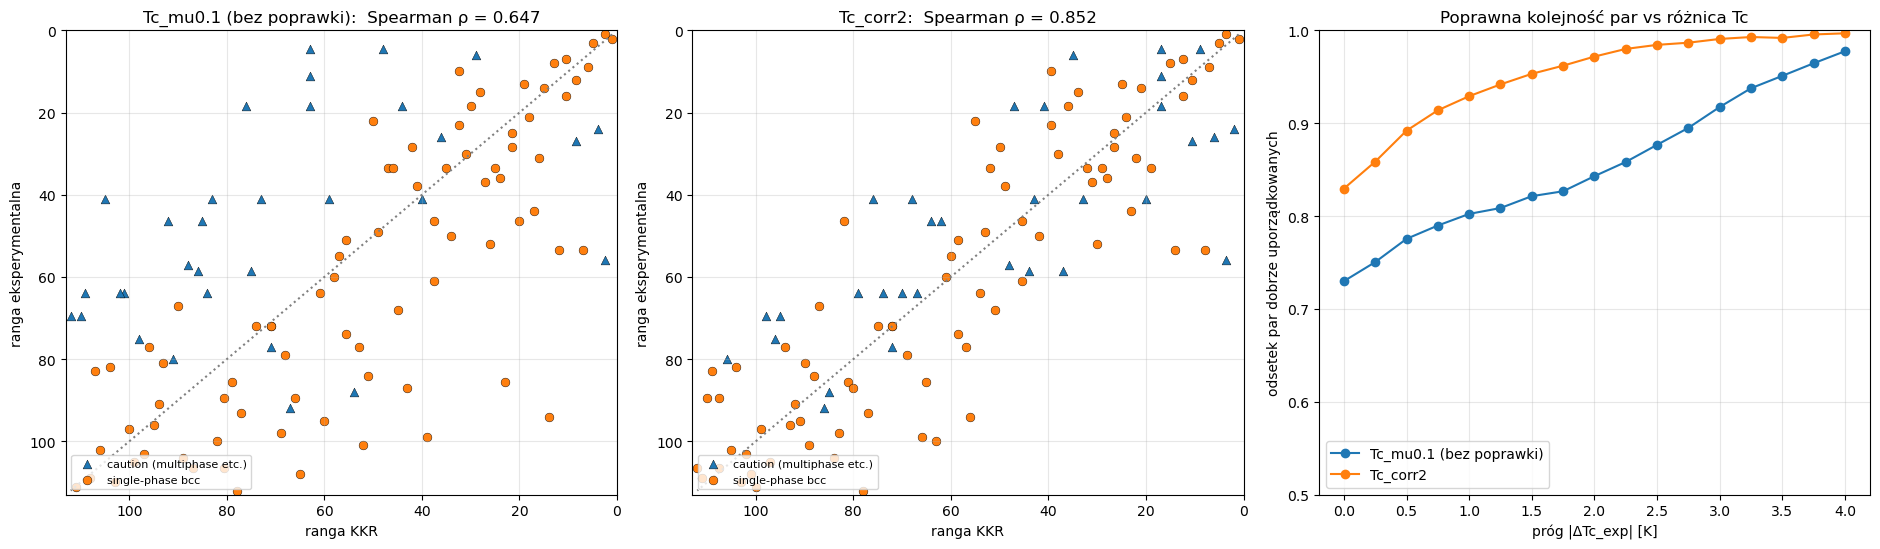

Kendall τ między rankingami KKR Tc_mu0.1 i Tc_corr2: 0.650


In [8]:
ordering_plot(DF)

## 5. Tabela stopów (posortowana po Tc_exp)

In [9]:
alloy_table(DF)

,name,author,group,Tc_exp,theta_mix,lambda_mix,theta_corr,lambda_es,Tc_mu0.1,Tc_corr2,KKR/exp Tc_mu0.1,KKR/exp Tc_corr2
0,Nb67HfZrTi33,von Rohr,single-phase bcc,9.36,287.650,0.877,287.650,0.000,13.311,13.311,1.422,1.422
1,(TiHfTa)1-xNbx_x0.9,Li,single-phase bcc,9.11,277.833,0.915,277.833,0.000,13.858,13.858,1.521,1.521
2,(TiHfTa)1-xNbx_x0.75,Li,single-phase bcc,8.82,282.083,0.830,282.083,0.000,11.775,11.775,1.335,1.335
3,ScNbTiZr,Krnel,caution (multiphase etc.),8.40,322.900,0.640,297.700,0.000,7.351,10.134,0.875,1.206
4,ScNbTiZr_nominal,Krnel,caution (multiphase etc.),8.40,330.000,0.588,295.000,0.000,5.867,9.546,0.698,1.136
5,NbTaTiZr_Wu2018,Wu,caution (multiphase etc.),8.29,294.000,0.698,294.000,0.000,8.405,8.405,1.014,1.014
6,TiZrNb_Kosuth,Košuth,single-phase bcc,8.20,321.667,0.711,321.667,0.000,9.628,9.628,1.174,1.174
7,(TiHfTa)1-xNbx_x0.57,Li,single-phase bcc,8.19,287.183,0.747,287.183,0.000,9.612,9.612,1.174,1.174
8,NbZr75TiHf25,Idczak,single-phase bcc,8.17,288.125,0.792,288.125,0.000,10.949,10.949,1.340,1.340
9,TaNbZrTi_Krishnan,Krishnan,single-phase bcc,8.12,301.250,0.687,301.250,0.000,8.268,8.268,1.018,1.018


## 6. Stopy, które poprawka zmienia najbardziej

`ratio` = KKR/exp przed (`Tc_mu0.1`) i po (`Tc_corr2`). Stopy ze Sc zyskują (niższe θ_corr, wyższe λ), stopy z V tracą (λ_es).

In [10]:
ch = DF[['name', 'group', 'Tc_exp', 'Tc_mu0.1', 'Tc_corr2', 'theta_mix', 'theta_corr', 'lambda_mix', 'lambda_corr',
         'lambda_es', 'Ti', 'Sc', 'V']].copy()
ch['ratio przed'] = ch['Tc_mu0.1'] / ch.Tc_exp
ch['ratio po'] = ch.Tc_corr2 / ch.Tc_exp
ch = ch[(ch.Tc_corr2 - ch['Tc_mu0.1']).abs() > 1e-9]
print(f'zmienionych wierszy: {len(ch)} z {len(DF)}')
ch.reindex((ch.Tc_corr2 - ch['Tc_mu0.1']).abs().sort_values(ascending=False).index).round(3)

zmienionych wierszy: 47 z 112


,name,group,Tc_exp,Tc_mu0.1,Tc_corr2,theta_mix,theta_corr,lambda_mix,lambda_corr,lambda_es,Ti,Sc,V,ratio przed,ratio po
102,NbV67HfZrTi33,single-phase bcc,7.20,8.873,4.814,322.825,322.825,0.687,0.687,0.065,0.110,0.000,0.335,1.232,0.669
87,ScNbTiZr_nominal,caution (multiphase etc.),8.40,5.867,9.546,330.000,295.000,0.588,0.736,0.000,0.250,0.250,0.000,0.698,1.136
89,NbScTiZr_Kitagawa,caution (multiphase etc.),8.11,5.867,9.546,330.000,295.000,0.588,0.736,0.000,0.250,0.250,0.000,0.723,1.177
90,NbScTiZr_Seki,caution (multiphase etc.),7.90,5.867,9.546,330.000,295.000,0.588,0.736,0.000,0.250,0.250,0.000,0.743,1.208
85,ScHfNbZr_nominal,caution (multiphase etc.),6.80,4.554,8.158,287.500,252.500,0.567,0.735,0.000,0.000,0.250,0.000,0.670,1.200
91,Hf10Nb25Sc25Ti20Zr20,caution (multiphase etc.),6.83,4.424,7.819,320.500,285.500,0.544,0.686,0.000,0.200,0.250,0.000,0.648,1.145
92,Hf5Nb45Sc20Ti15Zr15,caution (multiphase etc.),7.69,8.022,11.236,310.750,282.750,0.670,0.810,0.000,0.150,0.200,0.000,1.043,1.461
108,V57Ti29W14,single-phase bcc,5.00,5.564,2.367,394.286,394.286,0.548,0.548,0.058,0.286,0.000,0.571,1.113,0.473
13,ScHfNbZr,caution (multiphase etc.),6.80,5.187,8.295,284.050,254.650,0.593,0.738,0.000,0.000,0.210,0.000,0.763,1.220
31,TaNbHfZrSc,caution (multiphase etc.),7.40,5.202,8.177,278.000,250.000,0.598,0.739,0.000,0.000,0.200,0.000,0.703,1.105


## Wnioski (2026-11-05)

| podzbiór | n | τ: Tc_mu0.1 → Tc_corr2 | MAE [K] | mediana KKR/exp |
|---|---|---|---|---|
| skład B | 112 | 0.46 → 0.66 | 1.67 → 1.46 | 1.03 → 1.05 |
| single-phase bcc | 80 | 0.62 → 0.68 | 1.35 → 1.31 | 1.09 → 1.06 |
| z V lub Sc | 47 | 0.16 → 0.64 | 2.03 → 1.54 | 0.90 → 0.96 |
| ze Sc | 30 | 0.53 → 0.67 | 2.18 → 1.60 | 0.71 → 1.09 |
| ze Sc, single-phase | 6 | 0.97 → 0.83 | 0.56 → 1.08 | 0.94 → 1.10 |
| z V | 18 | 0.29 → 0.25 | 1.72 → 1.42 | 1.24 → 0.80 |
| bez V i Sc | 65 | 0.67 (bez zmian) | 1.40 | 1.06 |

Z poprawką corr2 skład B jest odtwarzany niemal tak dobrze jak skład A: τ 0.66 wobec 0.66 dla A.

**Gdzie corr2 pomaga, a gdzie nie.** Zmienia się tylko 47 wierszy z V lub Sc; pozostałe (65 wspólnych z A, 9 z Re/Ru) są
identyczne.
- **Wiersze z V lub Sc razem** (n = 47): τ 0.16 → 0.64, źle uporządkowanych par 48 % → 11 %, r 0.16 → 0.75. To jest
  główne źródło poprawy całego zbioru.
- **Ze Sc** (n = 30): τ 0.53 → 0.67, mediana KKR/exp 0.71 → 1.09. Zysk pochodzi głównie z próbek „caution”
  z 20–25 % Sc (Krnel, Kitagawa, Seki), które przed poprawką były zaniżone ok. 1.5×. **6 jednofazowych stopów ze Sc**
  (von Rohr 2018, Jangid 2024) pogarsza się: τ 0.97 → 0.83, MAE 0.56 → 1.08 K, mediana 0.94 → 1.10.
- **Z V** (n = 18): poprawka przestrzeliwuje. Bias zmienia znak z +1.4 na −0.9 K (mediana 1.24 → 0.80), MAE spada
  1.72 → 1.42 K, ale kolejność się nie poprawia (τ 0.29 → 0.25). Najmocniej obniżone są stopy z dużym V: NbV67HfZrTi33
  (V 34 %) 8.9 → 4.8 K przy 7.2 K w eksperymencie, V57Ti29W14 5.6 → 2.4 K przy 5.0 K. α_V = 0.4 dopasowano na liniach
  binarnych z warunkiem kolejności Nb–Zr > Nb–Ti > Ti–V, a dla wieloskładnikowych stopów z V jest za duże.
- **Z Ti ≥ 20 %** (n = 52 w B, 57 w A ∪ B): τ 0.29 → 0.66. Zmieniają się tu jednak tylko te stopy, które zawierają
  również V lub Sc; poprawka nie dotyka Ti.